# 3. Rule-based vs. data-driven attribution

Multi-touch attribution splits observed conversions across the touchpoints in each user's
path. The question here is whether any of the standard rules recovers how many conversions
each channel actually caused.

I simulate 50,000 users. Purchase intent is latent: high-intent users (20%) are more likely
to search and to open emails, and also more likely to buy no matter what. Each channel has a
true causal effect on conversion, so the simulator gives each channel's **incremental**
conversions exactly: the expected drop in conversions if that channel had not reached
the users it reached.

In [1]:
import sys
import warnings

warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from attribution import CHANNELS, TRUE_EFFECT, markov, rule_based, shapley, simulate_journeys

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
users, true_incr = simulate_journeys()
print(f"users: {len(users):,}  conversions: {users['converted'].sum():,}  "
      f"conversions with at least one touch: {users.loc[users['path'].str.len() > 0, 'converted'].sum():,}")
users[["path", "high_intent", "converted"]].head(8)

users: 50,000  conversions: 5,894  conversions with at least one touch: 5,454


,path,high_intent,converted
0,"[display, email, search]",True,True
1,[display],False,False
2,[display],False,False
3,[email],False,False
4,"[email, search]",True,True
5,"[social, display, email, search]",False,False
6,"[email, social]",False,False
7,"[display, email, search]",True,False


In [3]:
pd.DataFrame({
    "exposure rate": users[CHANNELS].mean(),
    "exposure rate, high intent": users.loc[users["high_intent"], CHANNELS].mean(),
    "conv. rate if exposed": [users.loc[users[c], "converted"].mean() for c in CHANNELS],
    "conv. rate if not exposed": [users.loc[~users[c], "converted"].mean() for c in CHANNELS],
    "true logit effect": pd.Series(TRUE_EFFECT),
}).round(3)

,exposure rate,"exposure rate, high intent",conv. rate if exposed,conv. rate if not exposed,true logit effect
display,0.499,0.497,0.129,0.107,0.25
social,0.346,0.346,0.136,0.108,0.35
email,0.299,0.496,0.178,0.092,0.30
search,0.262,0.700,0.250,0.071,0.50


The raw comparison already shows the problem: people who searched convert at a much
higher rate than those who did not, but most of that gap is intent, not search.

## Credit under each method

- **First touch / last touch:** all credit to one end of the path.
- **Linear:** equal split across the touches in the path.
- **Markov chain (removal effect):** fit a first-order transition matrix over
  start → channels → conversion/no conversion, and credit each channel in proportion
  to how much the conversion probability falls when the channel is removed.
- **Shapley:** a coalition's value is the conversions from users whose set of touched
  channels is contained in the coalition; credit is each channel's average marginal
  contribution.

In [4]:
credit = rule_based(users)
credit["markov"] = markov(users)
credit["shapley"] = shapley(users)
credit["true incremental"] = true_incr
credit.round(0)

,first_touch,last_touch,linear,markov,shapley,true incremental
display,2733,696,1607.0,1538.0,1608.0,554.0
social,1272,743,1111.0,1106.0,1111.0,555.0
email,965,978,1184.0,1121.0,1184.0,510.0
search,484,3037,1552.0,1689.0,1552.0,954.0


Attribution methods split **all** conversions among channels, including the ones that
would have happened anyway, so the totals are not comparable with the true incremental
counts. The fair comparison is each channel's **share** of credit.

In [5]:
share = credit / credit.sum()
share.round(3)

,first_touch,last_touch,linear,markov,shapley,true incremental
display,0.501,0.128,0.295,0.282,0.295,0.215
social,0.233,0.136,0.204,0.203,0.204,0.216
email,0.177,0.179,0.217,0.206,0.217,0.198
search,0.089,0.557,0.285,0.310,0.285,0.371


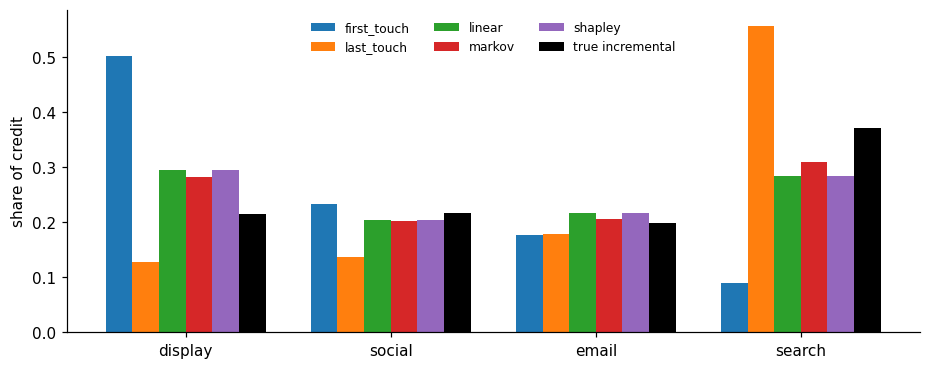

In [6]:
methods = ["first_touch", "last_touch", "linear", "markov", "shapley"]
fig, ax = plt.subplots(figsize=(10, 3.8))
width = 0.13
xpos = np.arange(len(CHANNELS))
for i, m in enumerate(methods + ["true incremental"]):
    ax.bar(xpos + (i - 2.5) * width, share[m], width, label=m,
           color="black" if m == "true incremental" else None)
ax.set_xticks(xpos, CHANNELS)
ax.set_ylabel("share of credit")
ax.legend(frameon=False, ncol=3, fontsize=8)
fig.savefig("../figures/attribution_shares.png", bbox_inches="tight")

In [7]:
err = (share[methods].sub(share["true incremental"], axis=0)).abs().sum() / 2
err.rename("share of credit misallocated (total variation distance)").round(3)

first_touch    0.303
last_touch     0.186
linear         0.099
markov         0.074
shapley        0.099
Name: share of credit misallocated (total variation distance), dtype: float64

## Takeaways

- **Attribution totals are not incrementality.** Every method hands out the 5,454 conversions
  that followed at least one touch. The channels caused about 2,570 of them; the rest came
  from users who would have bought anyway. Display, for example, gets 1,540 conversions under
  the Markov model and caused about 550.
- **The rules disagree mostly about search and display.** Last touch gives search 56% of the
  credit against a true incremental share of 37%, because search sits at the end of
  high-intent paths. First touch gives display half of the credit against a true 22%.
- **Data-driven methods get closer on shares in this simulation.** The Markov removal effect
  misallocates about 7% of credit, compared with 19% for last touch. That ranking depends on
  how this simulation is set up: both methods still only use who converted after which
  touch, so a stronger link between intent and exposure would move them away from the truth.
- **Shapley equals linear here.** With a coalition value equal to conversions from paths
  contained in the coalition, each path's conversions are split evenly among its channels,
  which is the linear rule. Shapley adds something only with a value function that compares
  conversion *rates* across channel sets, and that comparison is still confounded by intent.

Attribution is useful for comparing tactics within a channel. Budget decisions across
channels need incrementality from experiments like the geo holdout in notebook 2, which
can then calibrate the MMM.